# FraudShield — Model Training and Evaluation

## Objective
This notebook reviews the saved evaluation results for the fraud detection models.

### Models
1. Random Forest baseline
2. Isolation Forest (unsupervised anomaly detection)
3. Baseline XGBoost
4. Optuna-tuned XGBoost

### Evaluation metrics
- PR-AUC
- ROC-AUC
- Precision
- Recall
- False-positive rate

**Note:** This notebook reads existing model artifacts and reports. It does not retrain models.

In [1]:
#Cell 2 — Import libraries and define paths
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = BASE_DIR / "models"
REPORTS_DIR = BASE_DIR / "reports"

print("Project folder:", BASE_DIR)
print("Models folder exists:", MODELS_DIR.exists())
print("Reports folder exists:", REPORTS_DIR.exists())

Project folder: e:\project alml\ml task\week 3\FraudShield
Models folder exists: True
Reports folder exists: True


In [2]:
#Cell 3 — Load saved metrics
def load_json(path):
    if path.exists():
        with open(path, "r", encoding="utf-8") as file:
            return json.load(file)
    print("File not found:", path)
    return None

xgb_tuned = load_json(MODELS_DIR / "metrics_xgboost_tuned.json")
xgb_baseline = load_json(MODELS_DIR / "metrics_xgboost.json")
random_forest = load_json(MODELS_DIR / "metrics.json")
isolation_forest = load_json(REPORTS_DIR / "metrics_isolation_forest.json")
operating_point = load_json(REPORTS_DIR / "operating_point.json")

print("Loaded metrics:")
print("Tuned XGBoost:", xgb_tuned is not None)
print("Baseline XGBoost:", xgb_baseline is not None)
print("Random Forest:", random_forest is not None)
print("Isolation Forest:", isolation_forest is not None)
print("Operating point:", operating_point is not None)

Loaded metrics:
Tuned XGBoost: True
Baseline XGBoost: True
Random Forest: True
Isolation Forest: True
Operating point: True


In [3]:
#Cell 4 — Compare model metrics
records = []

model_reports = [
    ("Random Forest", random_forest),
    ("Baseline XGBoost", xgb_baseline),
    ("Tuned XGBoost", xgb_tuned),
    ("Isolation Forest", isolation_forest),
]

for model_name, report in model_reports:
    if report is None:
        continue

    records.append({
        "Model": model_name,
        "PR-AUC": report.get("test_pr_auc", report.get("pr_auc")),
        "ROC-AUC": report.get("test_roc_auc", report.get("roc_auc")),
        "Precision": report.get("test_precision", report.get("fraud_precision")),
        "Recall": report.get("test_recall", report.get("fraud_recall")),
    })

comparison_df = pd.DataFrame(records)
display(comparison_df.round(4))

,Model,PR-AUC,ROC-AUC,Precision,Recall
0,Random Forest,0.8196,0.9492,0.9818,0.72
1,Baseline XGBoost,0.7969,0.9881,0.7215,0.76
2,Tuned XGBoost,0.7908,0.9860,0.7600,0.76
3,Isolation Forest,0.0404,0.9501,0.0000,0.00


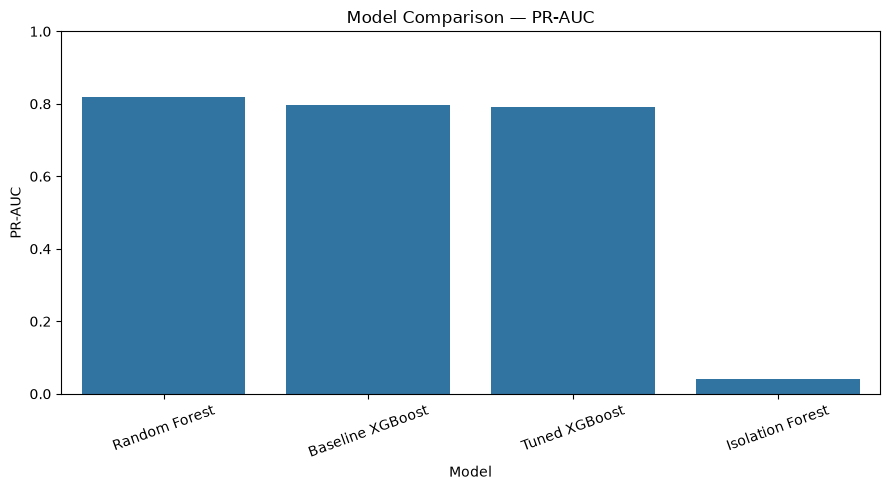

In [4]:
#Cell 5 — Visualize PR-AUC
plot_df = comparison_df.dropna(subset=["PR-AUC"])

plt.figure(figsize=(9, 5))
sns.barplot(data=plot_df, x="Model", y="PR-AUC")
plt.title("Model Comparison — PR-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

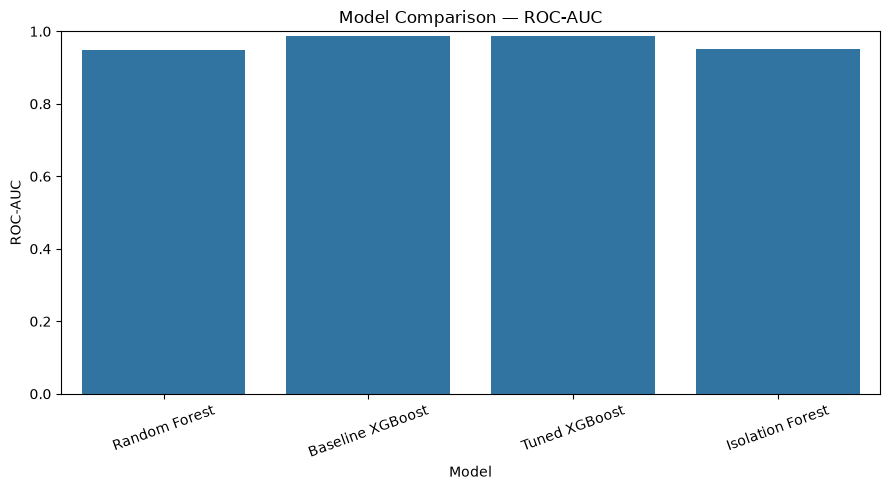

In [5]:
#Cell 6 — Visualize ROC-AUC
plot_df = comparison_df.dropna(subset=["ROC-AUC"])

plt.figure(figsize=(9, 5))
sns.barplot(data=plot_df, x="Model", y="ROC-AUC")
plt.title("Model Comparison — ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [6]:
#Cell 7 — Review operating threshold
if operating_point is not None:
    display(pd.DataFrame([operating_point]).T.rename(columns={0: "Value"}))
else:
    print("Operating-point report is missing.")

,Value
model,Optuna-tuned XGBoost
target_fpr,0.01
threshold,0.010172
validation_fpr,0.004702
validation_recall,0.865385
test_fpr,0.014854
test_recall_at_selected_threshold,0.866667
test_true_negatives,56042
test_false_positives,845
test_false_negatives,10


 ##Cell 8 — Markdown: interpretation
 ## Interpretation

- PR-AUC is especially useful for imbalanced fraud-detection data.
- ROC-AUC measures how well a model separates fraud and legitimate transactions across thresholds.
- Precision measures how many flagged transactions are actually fraudulent.
- Recall measures how many actual fraudulent transactions are detected.
- A lower threshold generally flags more transactions, which can increase recall but may also increase false positives.

### Important threshold distinction

The saved tuned XGBoost precision and recall metrics are evaluated at the conventional probability threshold of 0.5. The API uses a separately selected operating threshold stored in `reports/operating_point.json`.

These results must not be treated as identical: precision, recall, and false-positive rate depend on the selected threshold. The Isolation Forest results use its own anomaly-prediction rule.

## Conclusion

The notebook summarizes saved evaluation artifacts to support transparent model comparison. Final model selection should consider fraud recall, precision, false-positive workload, and PR-AUC—not accuracy alone.